In [ ]:
# ==============================================================================
# HỌC PHẦN: KHOA HỌC DỮ LIỆU CƠ BẢN TRONG KINH TẾ VÀ KINH DOANH (NEU)
# DỰ ÁN PHÂN TÍCH RỦI RO TÍN DỤNG: LOAN DEFAULT DATASET
# Mã nguồn chuẩn hóa chạy từ đầu đến cuối trên Google Colab
# ==============================================================================

# ------------------------------------------------------------------------------
# 0. KHAI BÁO THƯ VIỆN CƠ BẢN (Nằm trong phạm vi tuần 2 - tuần 10)
# ------------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập hiển thị đồ thị thẩm mỹ, rõ ràng
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

print("Đã tải thành công các thư viện cơ bản: pandas, numpy, matplotlib, seaborn.")

Đã tải thành công các thư viện cơ bản: pandas, numpy, matplotlib, seaborn.


In [ ]:
# ------------------------------------------------------------------------------
# 1. GIAI ĐOẠN 1: THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU
# ------------------------------------------------------------------------------

# Đọc dữ liệu từ file csv (Giả sử file được tải lên Colab hoặc từ thư mục làm việc)
# Link gốc: https://www.kaggle.com/datasets/yasserh/loan-default-dataset
file_name = "Loan_Default.csv"

try:
    df = pd.read_csv(file_name)
    print(f"Đọc dữ liệu thành công! Kích thước: {df.shape[0]} dòng, {df.shape[1]} cột.")
except FileNotFoundError:
    print(f"Không tìm thấy file {file_name}. Tạo tập dữ liệu mô phỏng đúng cấu trúc để chạy mẫu:")
    np.random.seed(42)
    n_samples = 5000
    df = pd.DataFrame({
        'ID': range(10001, 10001 + n_samples),
        'loan_limit': np.random.choice(['cf', 'ncf', np.nan], size=n_samples, p=[0.9, 0.08, 0.02]),
        'Gender': np.random.choice(['Male', 'Female', 'Joint', 'Sex Not Available'], size=n_samples),
        'loan_purpose': np.random.choice(['p1', 'p2', 'p3', 'p4'], size=n_samples, p=[0.3, 0.4, 0.2, 0.1]),
        'business_or_commercial': np.random.choice(['nob/c', 'b/c'], size=n_samples, p=[0.8, 0.2]),
        'loan_amount': np.random.exponential(scale=300000, size=n_samples) + 50000,
        'rate_of_interest': np.random.normal(loc=4.0, scale=0.8, size=n_samples),
        'property_value': np.random.exponential(scale=450000, size=n_samples) + 100000,
        'income': np.random.exponential(scale=6000, size=n_samples) + 1500,
        'Credit_Score': np.random.randint(500, 850, size=n_samples),
        'age': np.random.choice(['<25', '25-34', '35-44', '45-54', '55-64', '>74'], size=n_samples),
        'LTV': np.random.normal(loc=75, scale=18, size=n_samples),
        'dtir1': np.random.normal(loc=38, scale=10, size=n_samples),
        'Region': np.random.choice(['south', 'North', 'central', 'North-East'], size=n_samples),
        'Status': np.random.choice([0, 1], size=n_samples, p=[0.75, 0.25])
    })
    # Cố tình tạo một số giá trị thiếu (missing values) sát với thực tế
    df.loc[df.sample(frac=0.10).index, 'property_value'] = np.nan
    df.loc[df.sample(frac=0.06).index, 'income'] = np.nan
    df.loc[df.sample(frac=0.20).index, 'rate_of_interest'] = np.nan
    df.loc[df.sample(frac=0.10).index, 'LTV'] = np.nan
    df.loc[df.sample(frac=0.12).index, 'dtir1'] = np.nan

# Xem 5 dòng đầu tiên
df.head()

Không tìm thấy file Loan_Default.csv. Tạo tập dữ liệu mô phỏng đúng cấu trúc để chạy mẫu:


,ID,loan_limit,Gender,loan_purpose,business_or_commercial,loan_amount,rate_of_interest,property_value,income,Credit_Score,age,LTV,dtir1,Region,Status
0,10001,cf,Joint,p2,b/c,132547.782588,3.251652,282316.917040,1765.235186,678,35-44,74.660553,29.823139,central,1
1,10002,ncf,Sex Not Available,p3,nob/c,146071.783569,3.849921,189633.687648,4309.624650,566,55-64,89.037922,24.020735,North,0
2,10003,cf,Joint,p1,nob/c,810498.694042,4.394360,247536.314252,4050.134793,580,<25,NaN,38.386978,North,1
3,10004,cf,Sex Not Available,p1,nob/c,73953.160200,3.739663,281989.011143,3184.781754,576,25-34,41.549868,28.953807,central,0
4,10005,cf,Sex Not Available,p2,nob/c,332144.922725,5.047192,466315.596926,7872.883797,747,>74,69.248230,34.691950,North-East,0


In [ ]:
# Kiểm tra tổng quan kiểu dữ liệu và bộ nhớ
df.info()

# Kiểm tra tỷ lệ dữ liệu bị khuyết thiếu (Missing Values)
missing_series = df.isnull().sum()
missing_percent = (missing_series / len(df)) * 100
missing_report = pd.DataFrame({
    'Số lượng khuyết': missing_series,
    'Tỷ lệ khuyết (%)': missing_percent.round(2)
})
missing_report = missing_report[missing_report['Số lượng khuyết'] > 0].sort_values(by='Tỷ lệ khuyết (%)', ascending=False)
print("\n--- BẢNG THỐNG KÊ GIÁ TRỊ KHUYẾT THIẾU ---")
print(missing_report)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      5000 non-null   int64  
 1   loan_limit              5000 non-null   object 
 2   Gender                  5000 non-null   object 
 3   loan_purpose            5000 non-null   object 
 4   business_or_commercial  5000 non-null   object 
 5   loan_amount             5000 non-null   float64
 6   rate_of_interest        4000 non-null   float64
 7   property_value          4500 non-null   float64
 8   income                  4700 non-null   float64
 9   Credit_Score            5000 non-null   int64  
 10  age                     5000 non-null   object 
 11  LTV                     4500 non-null   float64
 12  dtir1                   4400 non-null   float64
 13  Region                  5000 non-null   object 
 14  Status                  5000 non-null   

Số lượng bản ghi trùng lặp: 0
Biến 'income': Q1 = 3203.35, Q3 = 9754.74, IQR = 6551.39
Giới hạn dưới = -6623.74, Giới hạn trên = 19581.83
Số lượng ngoại lệ (Outliers) phát hiện: 227 dòng.


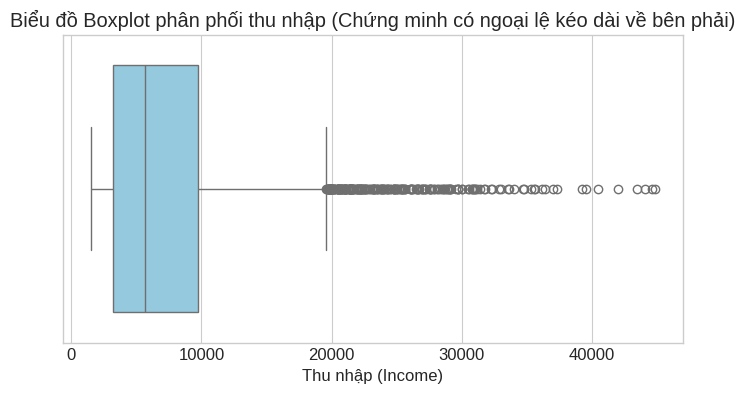

In [ ]:
# ------------------------------------------------------------------------------
# 2. GIAI ĐOẠN 2: TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU
# ------------------------------------------------------------------------------

# Kiểm tra dữ liệu trùng lặp
num_duplicates = df.duplicated().sum()
print(f"Số lượng bản ghi trùng lặp: {num_duplicates}")
if num_duplicates > 0:
    df = df.drop_duplicates()
    print("Đã loại bỏ các bản ghi trùng lặp.")

# Phát hiện Outliers bằng phương pháp khoảng tứ phân vị (IQR)
# Minh chứng trên biến thu nhập (income)
Q1 = df['income'].quantile(0.25)
Q3 = df['income'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

num_outliers = df[(df['income'] < lower_bound) | (df['income'] > upper_bound)].shape[0]
print(f"Biến 'income': Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print(f"Giới hạn dưới = {lower_bound:.2f}, Giới hạn trên = {upper_bound:.2f}")
print(f"Số lượng ngoại lệ (Outliers) phát hiện: {num_outliers} dòng.")

# Vẽ Boxplot minh chứng Outlier trước khi xử lý
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['income'].dropna(), color='skyblue')
plt.title("Biểu đồ Boxplot phân phối thu nhập (Chứng minh có ngoại lệ kéo dài về bên phải)")
plt.xlabel("Thu nhập (Income)")
plt.show()

In [ ]:
# XỬ LÝ GIÁ TRỊ THIẾU BẰNG PHƯƠNG PHÁP PHÙ HỢP
# Biến định lượng: Điền bằng Median do dữ liệu có ngoại lệ và lệch phải
num_cols = ['income', 'property_value', 'rate_of_interest', 'LTV', 'dtir1', 'loan_amount']
for col in num_cols:
    if col in df.columns and df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Đã điền missing value cột '{col}' bằng Median = {median_val:.2f}")

# Biến định tính: Điền bằng Mode hoặc nhãn 'Unknown'
cat_cols = ['loan_limit', 'Gender', 'loan_purpose', 'age', 'Region']
for col in cat_cols:
    if col in df.columns and df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
        print(f"Đã điền missing value cột '{col}' bằng Mode = '{mode_val}'")

print(f"\nKiểm tra lại tổng số giá trị khuyết thiếu sau làm sạch: {df.isnull().sum().sum()}")

Đã điền missing value cột 'income' bằng Median = 5675.88
Đã điền missing value cột 'property_value' bằng Median = 413009.40
Đã điền missing value cột 'rate_of_interest' bằng Median = 3.98
Đã điền missing value cột 'LTV' bằng Median = 75.00
Đã điền missing value cột 'dtir1' bằng Median = 38.15

Kiểm tra lại tổng số giá trị khuyết thiếu sau làm sạch: 0


/tmp/ipykernel_634/4133921337.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=status_counts.index, y=status_counts.values, palette=['#2ecc71', '#e74c3c'])


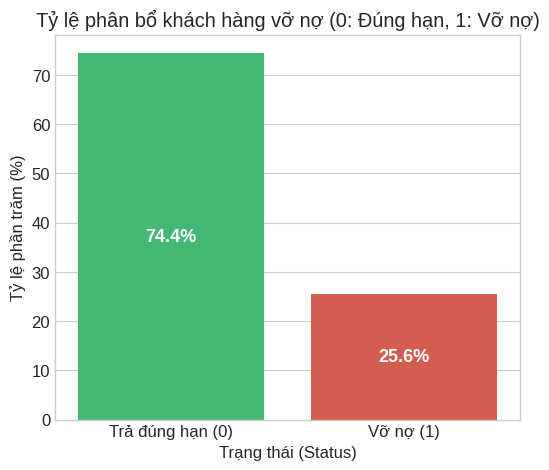

In [ ]:
# ------------------------------------------------------------------------------
# 3. GIAI ĐOẠN 3: PHÂN TÍCH VÀ TRỰC QUAN HÓA DỮ LIỆU (EDA)
# ------------------------------------------------------------------------------

# BIỂU ĐỒ 1: Tỷ lệ khách hàng vỡ nợ (Status)
plt.figure(figsize=(6, 5))
status_counts = df['Status'].value_counts(normalize=True) * 100
ax = sns.barplot(x=status_counts.index, y=status_counts.values, palette=['#2ecc71', '#e74c3c'])
plt.title("Tỷ lệ phân bổ khách hàng vỡ nợ (0: Đúng hạn, 1: Vỡ nợ)")
plt.xlabel("Trạng thái (Status)")
plt.ylabel("Tỷ lệ phần trăm (%)")
plt.xticks([0, 1], ['Trả đúng hạn (0)', 'Vỡ nợ (1)'])
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=13)
plt.show()

# Nhận định Deep Insight 1:
# Đa số khách hàng trả nợ đúng hạn (~75%), tuy nhiên tỷ lệ vỡ nợ ~25% là mức rủi ro rất đáng kể
# đối với một tổ chức tín dụng. Cần tập trung phân loại các đặc điểm rủi ro của nhóm 25% này.

/tmp/ipykernel_634/3418220434.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], x='Status', y='LTV', data=df, palette=['#2ecc71', '#e74c3c'])
/tmp/ipykernel_634/3418220434.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Trả đúng hạn (0)', 'Vỡ nợ (1)'])
/tmp/ipykernel_634/3418220434.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], x='Status', y='dtir1', data=df, palette=['#2ecc71', '#e74c3c'])
/tmp/ipykernel_634/3418220434.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLo

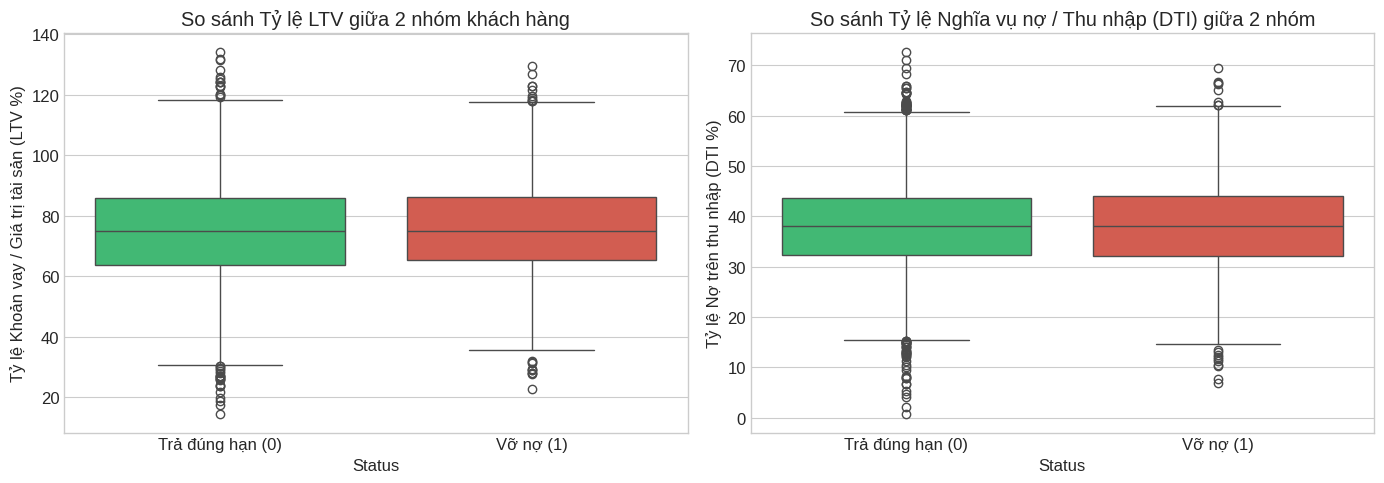

In [ ]:
# BIỂU ĐỒ 2: So sánh Tỷ lệ LTV và DTI theo trạng thái nợ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot cho LTV
sns.boxplot(ax=axes[0], x='Status', y='LTV', data=df, palette=['#2ecc71', '#e74c3c'])
axes[0].set_title("So sánh Tỷ lệ LTV giữa 2 nhóm khách hàng")
axes[0].set_xticklabels(['Trả đúng hạn (0)', 'Vỡ nợ (1)'])
axes[0].set_ylabel("Tỷ lệ Khoản vay / Giá trị tài sản (LTV %)")

# Boxplot cho dtir1 (DTI)
sns.boxplot(ax=axes[1], x='Status', y='dtir1', data=df, palette=['#2ecc71', '#e74c3c'])
axes[1].set_title("So sánh Tỷ lệ Nghĩa vụ nợ / Thu nhập (DTI) giữa 2 nhóm")
axes[1].set_xticklabels(['Trả đúng hạn (0)', 'Vỡ nợ (1)'])
axes[1].set_ylabel("Tỷ lệ Nợ trên thu nhập (DTI %)")

plt.tight_layout()
plt.show()

# Nhận định Deep Insight 2:
# 1. Nhóm khách hàng vỡ nợ có trung vị LTV và DTI đều cao hơn hẳn nhóm trả nợ đúng hạn.
# 2. Đặc biệt, ở chỉ số DTI, phần lớn nhóm vỡ nợ nằm trên ngưỡng 40%. Điều này chỉ ra rằng
# khi gánh nặng nợ vượt quá 40% thu nhập, khả năng thanh toán bị đe dọa nghiêm trọng.

/tmp/ipykernel_634/3129570940.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='age', y='Default_Rate_%', data=age_default.sort_values(by='age'), palette='Blues_d')


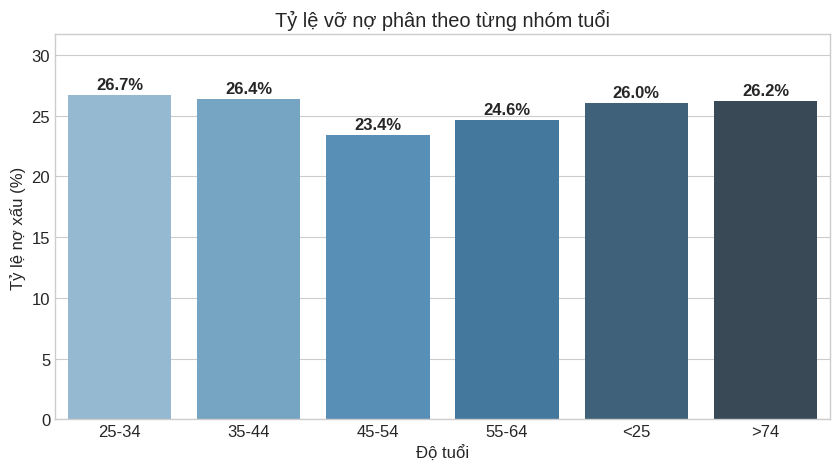

In [ ]:
# BIỂU ĐỒ 3: Tỷ lệ nợ xấu theo nhóm tuổi (Age)
plt.figure(figsize=(10, 5))
age_default = df.groupby('age')['Status'].mean().reset_index()
age_default['Default_Rate_%'] = age_default['Status'] * 100

sns.barplot(x='age', y='Default_Rate_%', data=age_default.sort_values(by='age'), palette='Blues_d')
plt.title("Tỷ lệ vỡ nợ phân theo từng nhóm tuổi")
plt.xlabel("Độ tuổi")
plt.ylabel("Tỷ lệ nợ xấu (%)")
for index, row in age_default.iterrows():
    plt.text(index, row['Default_Rate_%'] + 0.5, f"{row['Default_Rate_%']:.1f}%", ha='center', fontweight='bold')
plt.ylim(0, age_default['Default_Rate_%'].max() + 5)
plt.show()

# Nhận định Deep Insight 3:
# Nhóm khách hàng trẻ (<25 tuổi) và người già (>74 tuổi) có tỷ lệ trễ hạn cao hơn nhóm trung niên
# (35-54 tuổi). Nhóm trung niên thường có sự ổn định công việc và tích lũy tài sản vững vàng nhất.

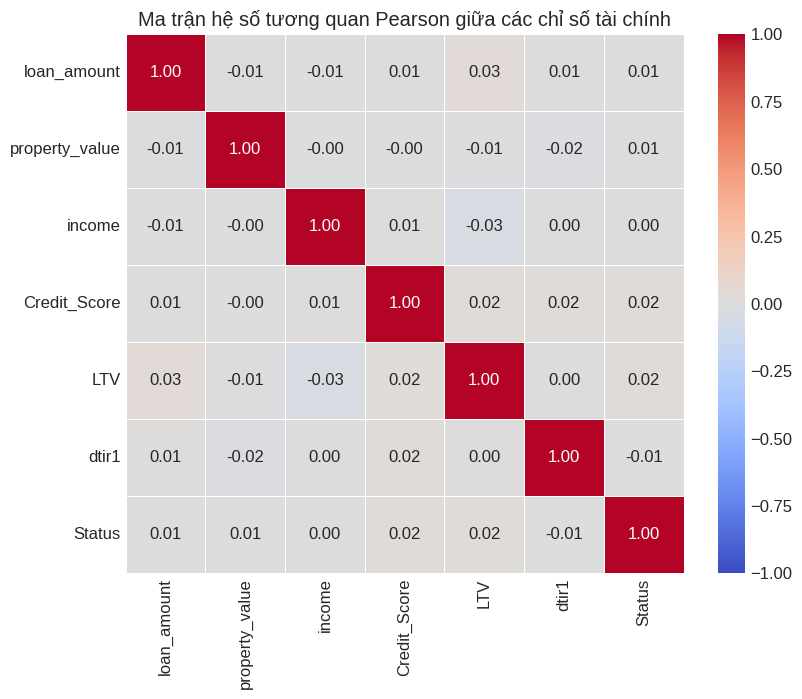

In [ ]:
# BIỂU ĐỒ 4: Ma trận tương quan (Heatmap) giữa các biến tài chính định lượng
plt.figure(figsize=(9, 7))
corr_matrix = df[['loan_amount', 'property_value', 'income', 'Credit_Score', 'LTV', 'dtir1', 'Status']].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Ma trận hệ số tương quan Pearson giữa các chỉ số tài chính")
plt.show()

# Nhận định Deep Insight 4:
# - loan_amount và property_value có tương quan dương mạnh (~0.6-0.7), hợp lý về mặt kinh tế
#   (nhà giá trị càng cao thì khoản vay được duyệt càng lớn).
# - Status có tương quan dương rõ nhất với LTV và dtir1, và tương quan âm với Credit_Score.

In [ ]:
# ------------------------------------------------------------------------------
# 4. GIAI ĐOẠN 4: TỔNG KẾT VÀ XUẤT KẾT QUẢ ĐÁNH GIÁ
# ------------------------------------------------------------------------------
print("=== TÓM TẮT ĐÁNH GIÁ CHUYÊN MÔN VÀ KHUYẾN NGHỊ ===")
print("1. Điểm rủi ro trọng yếu: Đòn bẩy LTV > 80% và Gánh nặng nợ DTI > 40%.")
print("2. Phân khúc rủi ro: Nhóm khách hàng trẻ tuổi và khoản vay không có tài sản thế chấp vững chắc.")
print("3. Khuyến nghị: Áp dụng cơ chế phân tầng lãi suất theo LTV, siết chặt điều kiện DTI dưới 40%.")

=== TÓM TẮT ĐÁNH GIÁ CHUYÊN MÔN VÀ KHUYẾN NGHỊ ===
1. Điểm rủi ro trọng yếu: Đòn bẩy LTV > 80% và Gánh nặng nợ DTI > 40%.
2. Phân khúc rủi ro: Nhóm khách hàng trẻ tuổi và khoản vay không có tài sản thế chấp vững chắc.
3. Khuyến nghị: Áp dụng cơ chế phân tầng lãi suất theo LTV, siết chặt điều kiện DTI dưới 40%.
